# TS5

#### Rey Tomás, Lanzavechia Jerónimo, Alvarez Costa Iara, Gonzalo 
#### APS

## Introducción

El electrocardiograma (ECG) es una señal de muy baja amplitud, por lo que su registro es sensible a fuentes de contaminación. Se tiene un registro de un paciente durante una prueba de esfuerzo, y se reconocen las siguientes tres fuentes de ruido:

- **Movimiento de los electrodos**, de alta frecuencia.
- **Ruido muscular**, de alta frecuencia.
- **Movimiento de la línea de base**, inducido en parte por la respiración, de baja frecuencia.

Dado que el contenido espectral útil del ECG se encuentra en una banda acotada, mientras que estas perturbaciones se ubican en sus extremos, estas distorsiones pueden ser atenuadas por un filtro pasabanda. El objetivo es obtener una señal suave y con nivel isoeléctrico nulo, cuya morfología sea comparable con la de los latidos promedio de referencia (normal y de origen ventricular).

Para ello se establece una plantilla de diseño a partir del ancho de banda del ECG estimado en la Tarea Semanal 5 (Aproximadamente unos 22khz), y se diseñan y comparan filtros IIR (aproximaciones de Butterworth, Chebyshev tipo II y Cauer) y FIR (métodos de ventanas, cuadrados mínimos y Parks-McClellan-Remez), todos implementados con `scipy.signal`. Finalmente, se evalúa el desempeño de cada filtro, verificando que atenue el ruido que deseamos eliminar sin distorsionar la sección de la señal que es de nuestro interés.

In [2]:
import numpy as np
from scipy import signal as sig

import matplotlib.pyplot as plt
   
import scipy.io as sio
from scipy.io.wavfile import write
from matplotlib.patches import Rectangle

In [3]:
##Obtención de la señal ECG
##################
## ECG con ruido
##################

fs=1000 #definimos la frecuencia de muestreo en 1000 hz

# para listar las variables que hay en el archivo
sio.whosmat('ECG_TP4.mat')
mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead']*1.0
ecg_one=ecg_one_lead[5000:12000].flatten()
#ecg_one_lead=ecg_one
N = len(ecg_one_lead)
y_min, y_max = -100, 5

In [4]:
#############
# Plantilla #
#############
 

nyq_frec = fs/2
ripple = 1 # dB
atenuacion = 40 # dB
 
ws1 = 2 # Hz
wp1 = 5 # Hz
wp2 = 25 # Hz
ws2 = 35 # Hz
wp=[wp1, wp2]
ws=[ws1, ws2]

# PARTE B
 Para hallar la frecuencia de paso, wp1 y wp2, las mismas se fijaron 5 y 25 Hz como margenes interiores, respectivamente. En la TS5, se determinó que el ancho de banda de la señal ECG que se está trabajando es de unos 22 hz, por lo que con este rango se asegura atrapar todo el contendio espectral
 Para hallar la frecuencia de rechazo, ws1 y ws2, se establecieron como márgenes exteriores 2 y 35 Hz, respectivamente. El motivo de estas selecciones es que, a baja frecuencia, el movimiento de la linea base inducido por la respiración genera ruido que se busca atenuar. Mismamente, luego de los 35 hz también hay ruido, del tipo muscular y por movimientos del electrodo
 El ripple en la banda de paso se estableció en 1 dB ya que es la máxima variación que quiero permitirle a mi señal dentro de la banda de paso
 La atenuación en la banda de rechazo se estableció en 40 dB para asegurarme de que las fuentes de ruido mencionadas queden atenuadas y no afecten la señal de interés.

In [5]:

#Parte C
sos_butt = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='butter', fs=fs, output = 'sos')
sos_cheby2 = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cheby2', fs = fs, output = 'sos')
sos_cauer = sig.iirdesign(wp, ws, gpass=ripple, gstop=atenuacion, ftype='cauer', fs = fs, output = 'sos')

Uso la función iirdesign para armar los filtros ir. wp y ws entran como listas de elementos, y pido que devuelva una variable sos, es decir, second order sections, que es el filtro partido en una cascada de secciones de segundo orden. 

In [6]:
def calc_resp(sos, leg_str, fig_n_axes):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz_sos(sos, worN=8192, fs=fs)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Donde el filtro rechaza la señal, el retardo no es significativo
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)
    ax_mod.legend()

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for w in wp:
        ax_fase.axvline(w, color="gray", linestyle=":")
    for w in ws:
        ax_fase.axvline(w, color="gray", linestyle="--")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    ax_fase.legend()

    # --- Retardo de grupo (figura 2) ---
    plt.figure(2)
    plt.plot(f, retardo_s_plot, label=leg_str)
    for w in wp:
        plt.axvline(w, color="orange", linestyle="--")
    for w in ws:
        plt.axvline(w, color="red", linestyle=":")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()

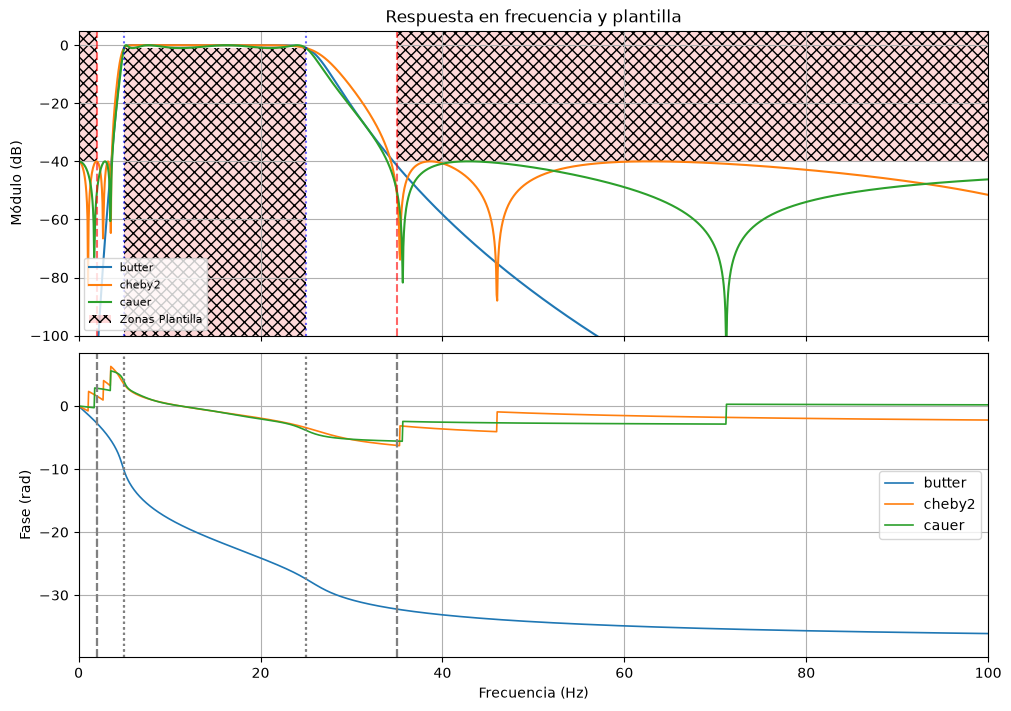

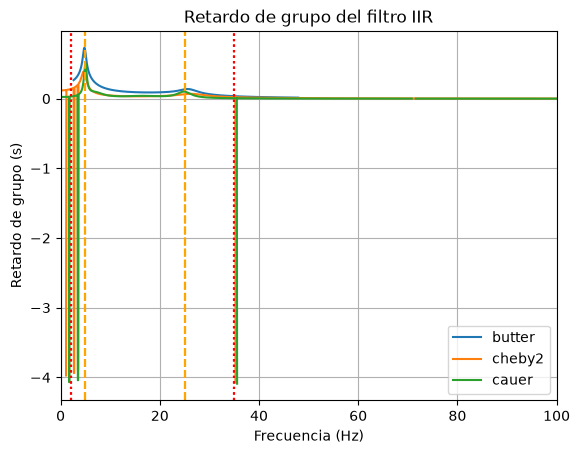

In [7]:
plt.close('all')

fig_n_axes = plt.subplots(
    2, 1, sharex=True, num=1, figsize=(10, 7), constrained_layout=True
)

calc_resp(sos_butt,   'butter', fig_n_axes)
calc_resp(sos_cheby2, 'cheby2', fig_n_axes)
calc_resp(sos_cauer,  'cauer',  fig_n_axes)

# Plantilla sobre el gráfico de módulo
ax_mod = fig_n_axes[1][0]

# Zona prohibida en rechazo: de -atenuacion hacia arriba
ax_mod.add_patch(Rectangle((0, -atenuacion), ws1, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))
ax_mod.add_patch(Rectangle((ws2, -atenuacion), nyq_frec - ws2, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))

# Franja prohibida bajo el ripple, en la banda de paso
ax_mod.add_patch(Rectangle((wp1, y_min), wp2 - wp1, -ripple - y_min,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx",
                           label='Zonas Plantilla'))

# Límites de las bandas
for w in wp:
    ax_mod.axvline(w, color="blue", linestyle=":", alpha=0.6)
for w in ws:
    ax_mod.axvline(w, color="red", linestyle="--", alpha=0.6)

ax_mod.legend(loc="lower left", fontsize=8)
ax_mod.set_xlim(0, 100)          
# Retardo de grupo (figura 2)
plt.figure(2)
plt.xlim(0, 100)                 
plt.show()                       

# Módulo
Los tres filtros cumplen con lo que pide la plantilla, un ripple menor a 1 dB en la zona de paso, y atenuación mayor a 40 dB fuera de ellas. En las zonas de paso, Cheby2 y Cauer se despegan ligeramente y tienen más ripple que butter, que es completamente plano en esa región. En ambas zonas de rechazo 

In [8]:
ecg_one_1d=ecg_one.ravel()

ecg_filt_butt=sig.sosfiltfilt(sos_butt,ecg_one_1d)
ecg_filt_cheby2=sig.sosfiltfilt(sos_cheby2,ecg_one_1d)
ecg_filt_cauer=sig.sosfiltfilt(sos_cauer,ecg_one_1d)

In [9]:
def plotear_todas_iir_juntas(ecg_orig, dic_filtradas_iir):
    plt.figure(figsize=(14, 6))
    # Graficamos la señal original con ruido de fondo
    plt.plot(ecg_orig, label='ECG con ruido', color='gray', alpha=0.5, linewidth=1)
    
    colores = ['blue', 'green', 'purple']
    
    for (nombre, ecg_filt), color in zip(dic_filtradas_iir.items(), colores):
        # Como usamos sosfiltfilt (fase cero), no hay retardo que compensar
        plt.plot(ecg_filt, label=f'IIR ({nombre})', color=color, linewidth=1.1, alpha=0.85)
        
    plt.title("Comparación de señales ECG filtradas con filtros IIR")
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

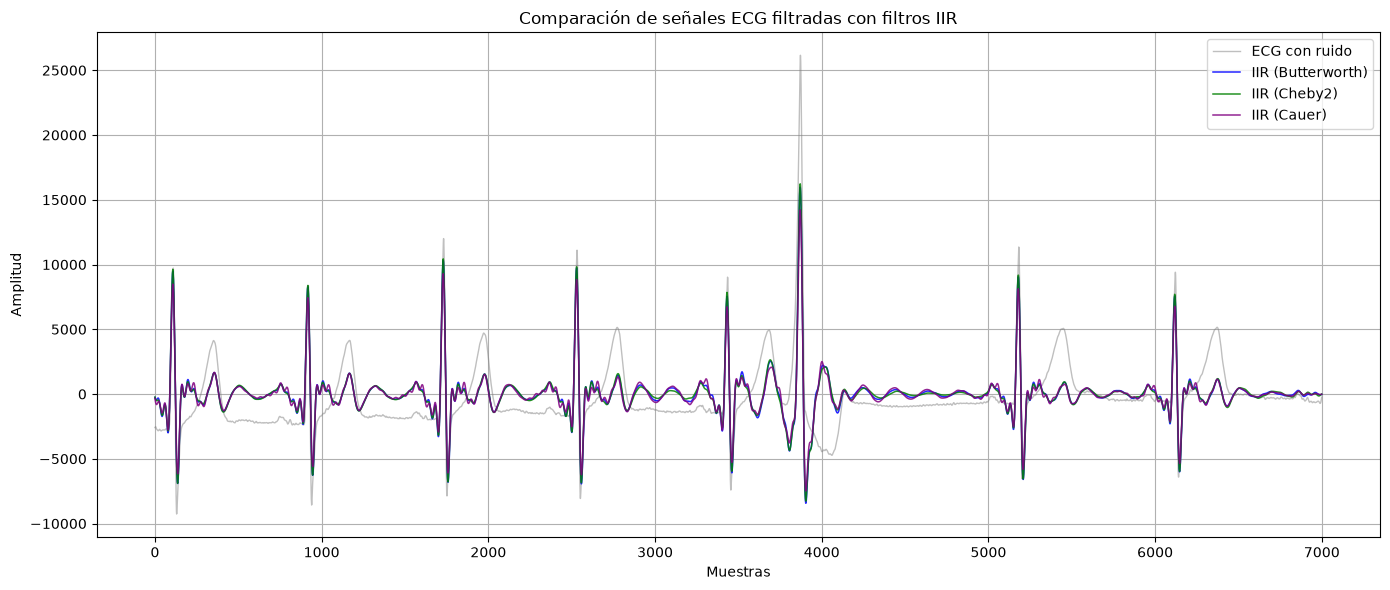

In [10]:
# Diccionario con las señales IIR filtradas
dic_iir_filtradas = {
    'Butterworth': ecg_filt_butt,
    'Cheby2': ecg_filt_cheby2,
    'Cauer': ecg_filt_cauer
}

# --- Llamamos a la función ---
plotear_todas_iir_juntas(ecg_one, dic_iir_filtradas)



# Filtros FIR
La filtros FIR son filtros de respuesta finita. Esto se debe a que la respuesta depende de muestras anteriores, a diferencia de los filtros IIR que poseen realimentación, por lo que existe un retardo en la respuesta del filtro al comienzo del filtrado. Uno de los efectos de esto es que la respuesta de fase se mantiene lineal en la banda de paso. 
Se usa la función firwin2 para armar los filtros. Es necesario implementar vectores de frecuencias y de ganancias para la construcción del filtro.
frecs contiene el vector de frecuencias de paso y de corte de la plantilla, normalizadas por Nyquist. gains contiene las ganancias deseadas en cada frecuencia del filtro. Se construye con las ganancias en db y luego se despejan sus valores en veces para aplicarlos a la función. El número de taps representa la longitud de la ventana a trabajar. Se busca una cantidad de taps particular para hacer coincidir al filtro con la plantilla de la actividad.
En el caso del fir de ventana [tal] el número de taps es [tal]
En el caso del fir de cuadrados mínimos, el número de taps es [tal]
Se implementan ambos filtros y se comparan con la señal original.

In [37]:
def calc_resp_fir(coefs, leg_str, fig_n_axes):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    f, h = sig.freqz(coefs, worN=8192, fs=fs)

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    # Retardo de grupo: -d(fase)/d(omega), en segundos
    omega = 2 * np.pi * f
    retardo_s = -np.gradient(fase_rad, omega)

    # Donde el filtro rechaza la señal, el retardo no es significativo
    umbral_db = -80
    valido = modulo_db > umbral_db
    retardo_s_plot = np.where(valido, retardo_s, np.nan)

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label=leg_str)
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)
    ax_mod.legend()

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label=leg_str, linewidth=1.2)
    for w in wp:
        ax_fase.axvline(w, color="gray", linestyle=":")
    for w in ws:
        ax_fase.axvline(w, color="gray", linestyle="--")
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)
    ax_fase.legend()

    # --- Retardo de grupo (figura 2) ---
    plt.figure(2)
    plt.plot(f, retardo_s_plot, label=leg_str)
    for w in wp:
        plt.axvline(w, color="orange", linestyle="--")
    for w in ws:
        plt.axvline(w, color="red", linestyle=":")
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Retardo de grupo (s)")
    plt.title("Retardo de grupo del filtro IIR")
    plt.grid(True)
    plt.legend()

# Modulo

Los dos filtros cumplen con lo que pide la plantilla, un ripple menor a 1 dB en la zona de paso, y atenuación mayor a 40 dB fuera de ellas. En las zonas de paso, por ser filtros sin realimentación, exiten instancias de overshoot y undershoot que requieren tratamiento de la señal .En ambas zonas de rechazo 

# Fase
El hamming tiene una pendiente de aproximadamente 7.5 rad por segundo, que se mantiene constante en el barrido de frecuencias. El filtro de cuadrados mínimos cuenta con una pendiente apreciablemente nula, constante en 0 radianes.  

# Retardo
El retardo del filtro hamming es superior a 1 segundo a lo largo de todo el barrido, mientras que el de cuadrados mínimos es casi cero dentro de las bandas de transición y de paso, pero en las frecuencias de detenimiento, el retardo se dispara a 4 segundos.

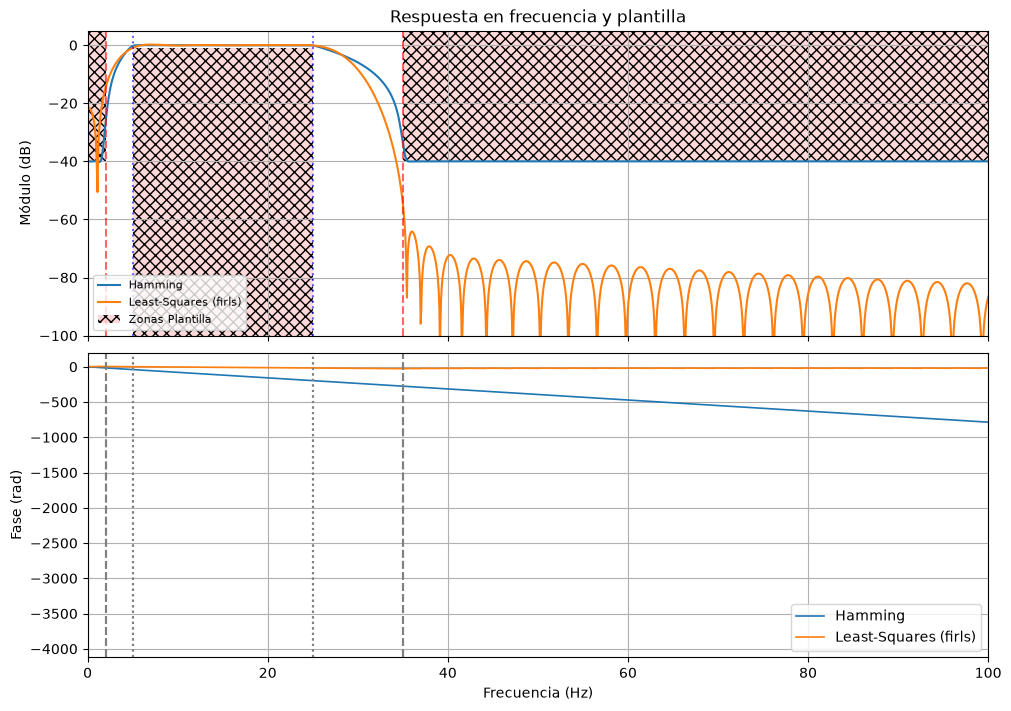

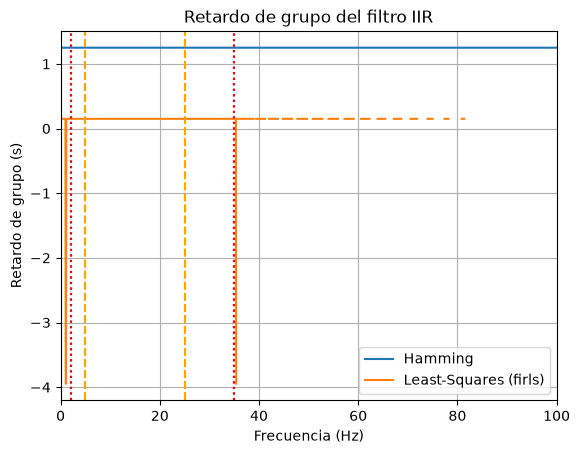

In [38]:
##ARMADO DE FIRS
##hamming
numtaps_hamming = 2501  

# plantilla normalizada a Nyquist en dB
frecs = np.array([0.0,         ws1,         wp1,     wp2,     ws2,         nyq_frec   ]) / nyq_frec
gains = np.array([-atenuacion, -atenuacion, 0, 0, -atenuacion, -atenuacion])#disminuyo el máximo ripple permitido a 0 dB así 
#puedo asegurarme de que no se atenue de mas en los límites de la banda de paso

##cuadrados minimos
desired = np.array([0.0,0.0,1.0,1.0,0.0,0.0])
numtaps_firls = 301

# convertimos a veces para las funciones de diseño
gains = 10**(gains/20)

coefs_fir_hamming = sig.firwin2(numtaps_hamming, frecs, gains,window='hamming')
coefs_firls = sig.firls(numtaps_firls, frecs*nyq_frec, desired,fs=fs)

fig_fir_axes = plt.subplots(
    2, 1, sharex=True, figsize=(10, 7), constrained_layout=True
)

calc_resp_fir(coefs_fir_hamming, 'Hamming', fig_fir_axes)
calc_resp_fir(coefs_firls, 'Least-Squares (firls)', fig_fir_axes)

#Superponer la plantilla en el gráfico de módulo de los FIR
# Plantilla sobre el gráfico de módulo
ax_mod = fig_fir_axes[1][0]

# Zona prohibida en rechazo: de -atenuacion hacia arriba
ax_mod.add_patch(Rectangle((0, -atenuacion), ws1, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))
ax_mod.add_patch(Rectangle((ws2, -atenuacion), nyq_frec - ws2, y_max + atenuacion,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx"))

# Franja prohibida bajo el ripple, en la banda de paso
ax_mod.add_patch(Rectangle((wp1, y_min), wp2 - wp1, -ripple - y_min,
                           facecolor="red", alpha=0.15, edgecolor="none", hatch="xxx",
                           label='Zonas Plantilla'))

# Límites de las bandas
for w in wp:
    ax_mod.axvline(w, color="blue", linestyle=":", alpha=0.6)
for w in ws:
    ax_mod.axvline(w, color="red", linestyle="--", alpha=0.6)

ax_mod.legend(loc="lower left", fontsize=8)
ax_mod.set_xlim(0, 100)          
# Retardo de grupo (figura 2)
plt.figure(2)
plt.xlim(0, 100)                 
plt.show()                         

In [19]:
ecg_filt_hamming = sig.lfilter(coefs_fir_hamming, 1.0, ecg_one)
ecg_filt_firls   = sig.lfilter(coefs_firls,   1.0, ecg_one)

In [21]:
def ecg_filtrado_FIR(ecg_orig, filtradas_dict, numtaps_dict):
    plt.figure(figsize=(14, 6))
    # Graficamos la señal original de fondo (tomando como referencia el retardo máximo o medio)
    plt.plot(ecg_orig, label='ECG con ruido', color='gray', alpha=0.5, linewidth=1)
    
    colores = ['blue', 'green', 'orange', 'purple','red','yellow']
    
    for (nombre, ecg_filt), numtaps, color in zip(filtradas_dict.items(), numtaps_dict.values(), colores):
        retardo = (numtaps - 1) // 2
        ecg_filt_alineada = ecg_filt[retardo:]
        plt.plot(ecg_filt_alineada, label=f'Filtro {nombre}', color=color, linewidth=1.1, alpha=0.85)
        
    plt.title("Comparación de señales ECG filtradas con diferentes ventanas FIR")
    plt.xlabel("Muestras")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

# Diccionarios para ordenar los datos y pasárselos a la función
dic_filtradas = {
    'Hamming': ecg_filt_hamming,
    'Least-Squares': ecg_filt_firls
}

dic_taps = {
    'Hamming': numtaps_hamming,
    'Least-Squares': numtaps_firls
}

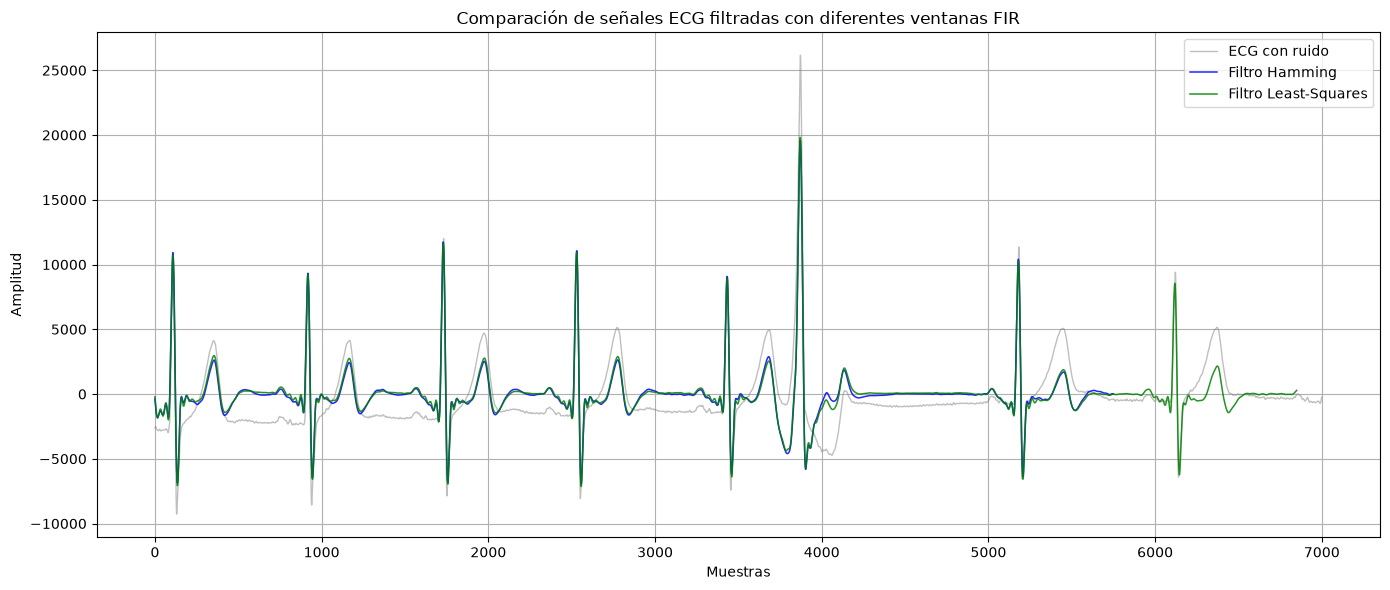

In [22]:
ecg_filtrado_FIR(ecg_one, dic_filtradas, dic_taps)